# Flood-It game analytics - presentation notebook

Reads the outputs of `python -m flood_it run` (metrics.json, data/*.csv, figures/). No numbers are computed here, so the notebook always matches the README, report and dashboard.

In [1]:
import json, pandas as pd
from pathlib import Path
from IPython.display import Image, display, Markdown
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
m = json.loads((ROOT / 'results/metrics.json').read_text(encoding='utf-8'))
csv = lambda n: pd.read_csv(ROOT / 'data' / f'{n}.csv')
fig = lambda n: display(Image(filename=str(ROOT / 'figures' / f'{n}.png')))
pd.set_option('display.max_columns', 20); pd.set_option('display.width', 160)

## 1. Data understanding
The export is sampled (constant events per day); most players were acquired before the window; some new players lack `first_open`.

In [2]:
pd.Series(m['profile']).to_frame('value').head(30)

,value
date_start,2018-06-12
date_end,2018-10-03
n_days,114
total_events,5700000
events_per_day_min,50000
events_per_day_max,50000
sampled_constant_daily_events,True
n_event_names,37
total_users,15175
users_android,7410


In [3]:
csv('p1_event_catalog').head(15)

,event_name,events_android,events_ios,users_android,users_ios,events_total,share_of_events,platform_coverage
0,screen_view,1076964,1170659,6475,7602,2247623,0.394320,both
1,user_engagement,742286,616672,6584,7004,1358958,0.238414,both
2,level_start_quickplay,290338,233092,4053,6113,523430,0.091830,both
3,level_end_quickplay,173138,176591,3039,5129,349729,0.061356,both
4,post_score,144772,97279,4379,4201,242051,0.042465,both
5,level_complete_quickplay,106062,85026,2163,3513,191088,0.033524,both
6,level_fail_quickplay,57924,79111,2355,3988,137035,0.024041,both
7,level_reset_quickplay,80250,42028,1609,1908,122278,0.021452,both
8,select_content,60275,44864,5375,5736,105139,0.018445,both
9,level_start,57320,17097,3315,1459,74417,0.013056,both


In [4]:
csv('p1_user_segments')

,segment,users,share
0,acquired_before_window,9086,0.598748
1,acquired_in_window_with_first_open,4307,0.283822
2,acquired_in_window_missing_first_open,1782,0.117430
3,other,0,0.000000


In [5]:
csv('p1_traffic_source_by_platform')

,platform,traffic_source,users
0,ANDROID,(direct),4250
1,ANDROID,google-play,3017
2,ANDROID,(null),64
3,ANDROID,google,48
4,ANDROID,invite_a_friend,21
5,ANDROID,firebase,5
6,ANDROID,AppLovin,3
7,ANDROID,Google,1
8,ANDROID,rj,1
9,IOS,(direct),7758


## 2. Growth
DAU spikes are an artefact: `screen_view` drops on those days and the fixed event budget is spread across more players.

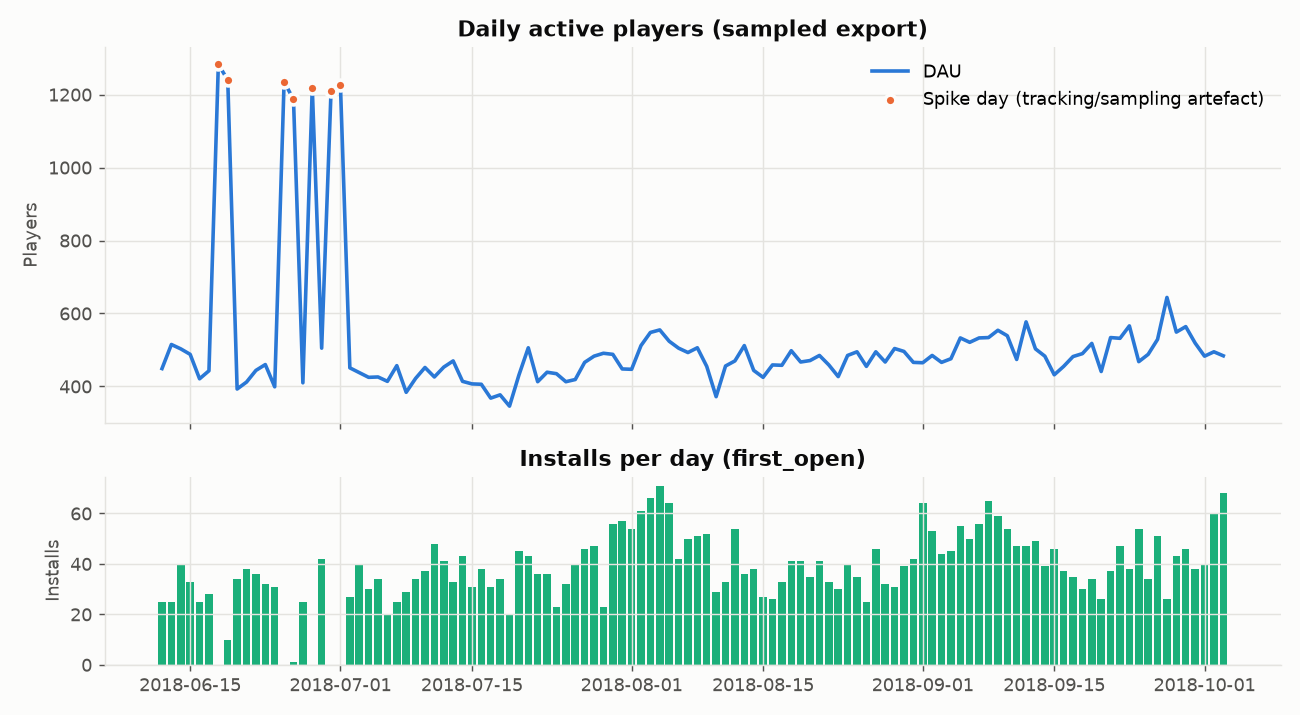

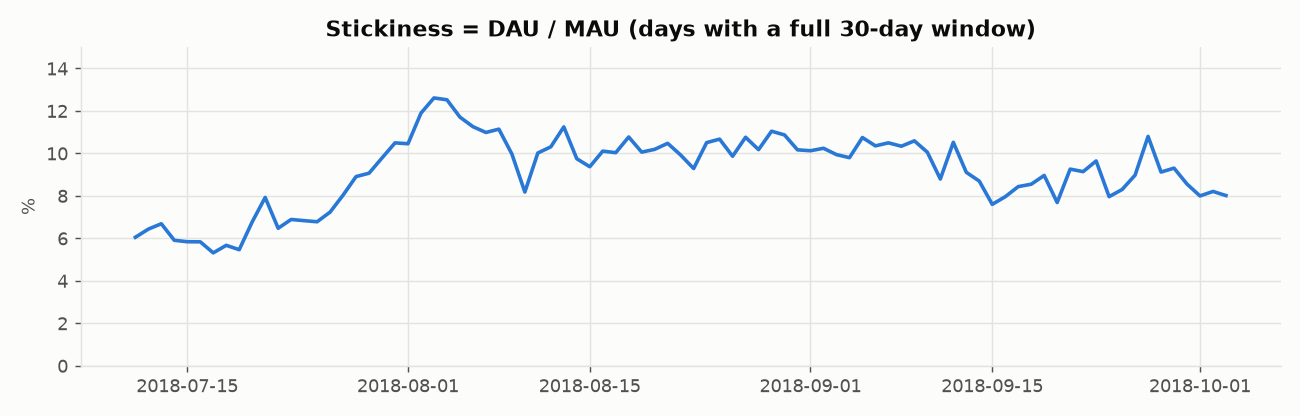

In [6]:
fig('fig01_dau_installs'); fig('fig02_stickiness')

In [7]:
display(csv('p2_dau_spikes')); csv('p2_spike_event_mix').head(10)

,activity_date,dau,installs,first_seen_users,returning_dau,events_per_dau,dau_vs_median,new_share
0,2018-06-18,1283,0,949,334,38.9712,2.71534,0.739673
1,2018-06-19,1240,10,545,695,40.3226,2.62434,0.439516
2,2018-06-25,1235,0,469,766,40.4858,2.61376,0.379757
3,2018-06-26,1187,1,373,814,42.1230,2.51217,0.314238
4,2018-06-28,1219,0,392,827,41.0172,2.57989,0.321575
5,2018-06-30,1211,0,375,836,41.2882,2.56296,0.309661
6,2018-07-01,1225,0,372,853,40.8163,2.59259,0.303673


,event_name,avg_events_normal_day,avg_events_spike_day,ratio_spike_vs_normal
0,screen_view,20915.500,3035.000,0.145107
1,user_engagement,11493.300,19836.700,1.725940
2,level_start_quickplay,4340.090,8160.860,1.880340
3,level_end_quickplay,2944.450,5680.290,1.929150
4,post_score,2039.820,2880.570,1.412170
5,level_complete_quickplay,1736.450,337.571,0.194403
6,level_fail_quickplay,1208.090,2284.140,1.890700
7,select_content,967.455,208.429,0.215440
8,level_reset_quickplay,923.091,1739.140,1.884040
9,level_start,608.818,1184.000,1.944750


## 3. Retention (right-censored players excluded)

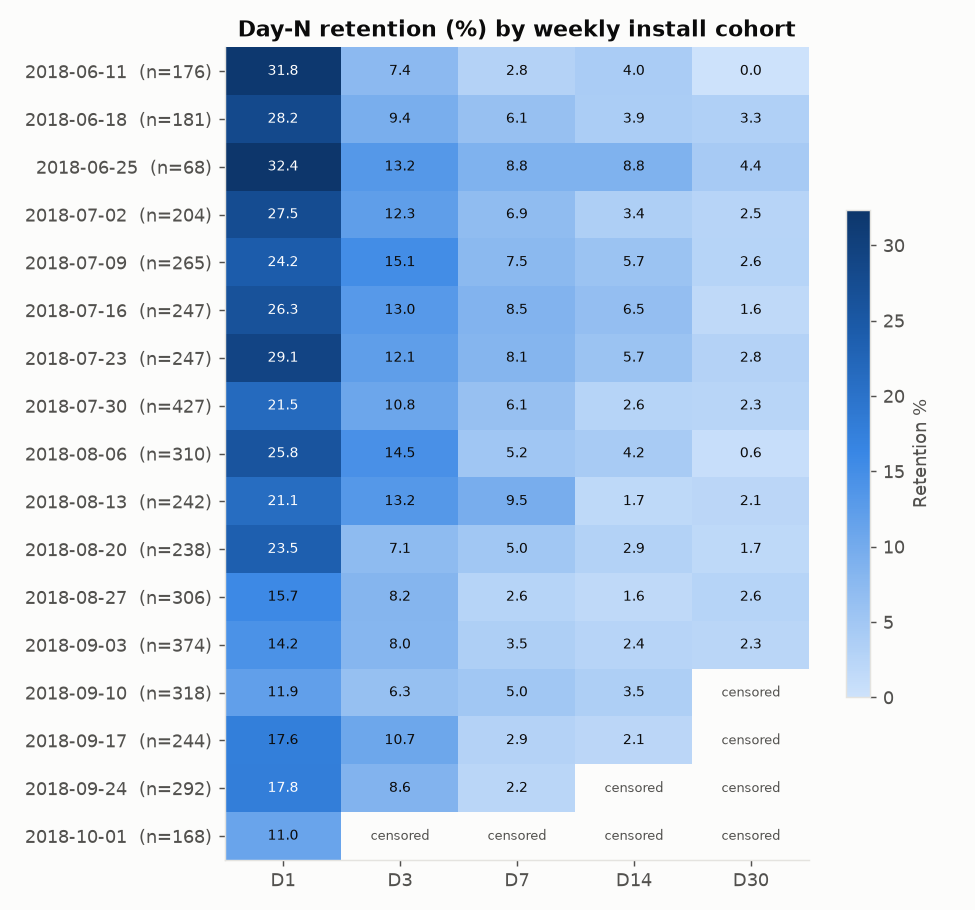

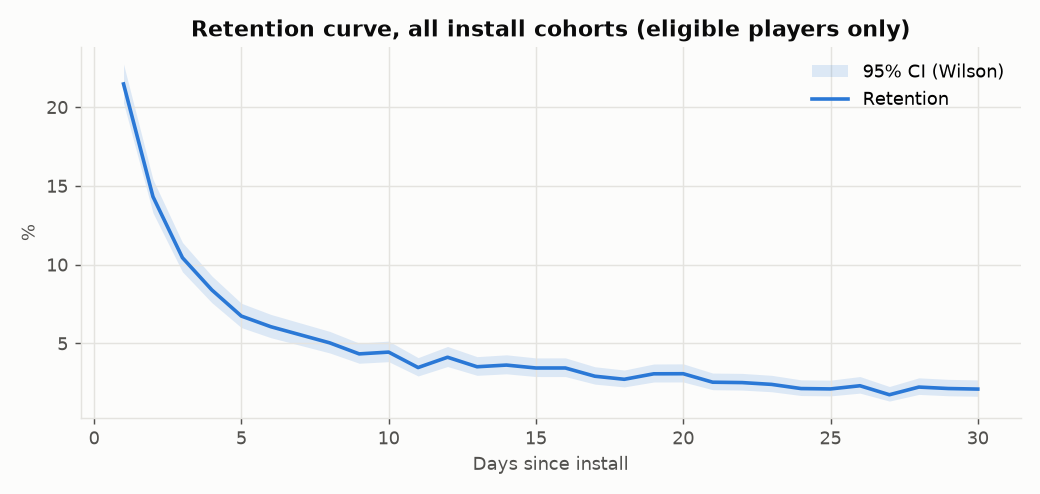

In [8]:
fig('fig03_retention_heatmap'); fig('fig04_retention_curve')

In [9]:
{k: v for k, v in m['retention'].items() if 'retention' in k}

{'d1_retention': 0.2147,
 'd3_retention': 0.1044,
 'd7_retention': 0.0554,
 'd14_retention': 0.0362,
 'd30_retention': 0.021,
 'd1_retention_android': 0.2269,
 'd3_retention_android': 0.1114,
 'd7_retention_android': 0.0581,
 'd14_retention_android': 0.0351,
 'd30_retention_android': 0.0204,
 'd1_retention_ios': 0.1895,
 'd3_retention_ios': 0.0902,
 'd7_retention_ios': 0.0502,
 'd14_retention_ios': 0.0388,
 'd30_retention_ios': 0.0226,
 'd1_retention_excl_spike_targets': 0.2118,
 'd7_retention_excl_spike_targets': 0.0558,
 'd1_retention_cohorts_jun_jul': 0.2634,
 'd1_retention_cohorts_sep': 0.1483}

## 4. Revenue & LTV

,platform,active_users,user_days,payers,purchases,revenue_usd,payer_rate,arpu_usd,arpdau_usd,arppu_usd
0,ALL,15175,59037,27,27,31.8563,0.001779,0.002099,0.000540,1.17986
1,ANDROID,7410,28181,11,11,11.8038,0.001484,0.001593,0.000419,1.07308
2,IOS,7765,30856,16,16,20.0525,0.002061,0.002582,0.000650,1.25328


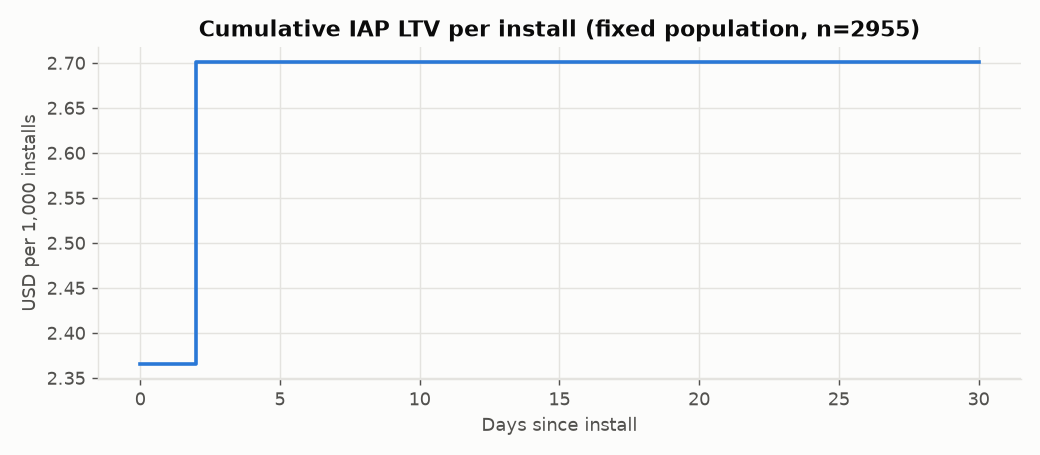

In [10]:
display(csv('p4_monetization_kpis')); fig('fig05_ltv_curve')

In [11]:
csv('p4_iap_transactions')[['activity_date','platform','currency','value_param','event_value_in_usd','revenue_usd','revenue_source','product_id']]

,activity_date,platform,currency,value_param,event_value_in_usd,revenue_usd,revenue_source,product_id
0,2018-06-17,ANDROID,USD,990000,NaN,0.990000,value_param_usd,extra_steps_pack_1
1,2018-06-21,IOS,USD,990000,NaN,0.990000,value_param_usd,remove_ads
2,2018-06-26,IOS,USD,4990000,NaN,4.990000,value_param_usd,extra_steps_pack_3
3,2018-06-28,IOS,USD,990000,0.990000,0.990000,event_value_in_usd,remove_ads
4,2018-06-28,ANDROID,USD,990000,0.990000,0.990000,event_value_in_usd,remove_ads
5,2018-06-30,IOS,USD,990000,0.990000,0.990000,event_value_in_usd,extra_steps_pack_1
6,2018-07-22,ANDROID,DKK,6300000,0.989404,0.989404,event_value_in_usd,extra_steps_pack_1
7,2018-07-25,IOS,USD,990000,0.990000,0.990000,event_value_in_usd,remove_ads
8,2018-07-31,IOS,TWD,30000000,0.980143,0.980143,event_value_in_usd,remove_ads
9,2018-07-31,ANDROID,TWD,32000000,1.045490,1.045490,event_value_in_usd,remove_ads


## 5. Levels

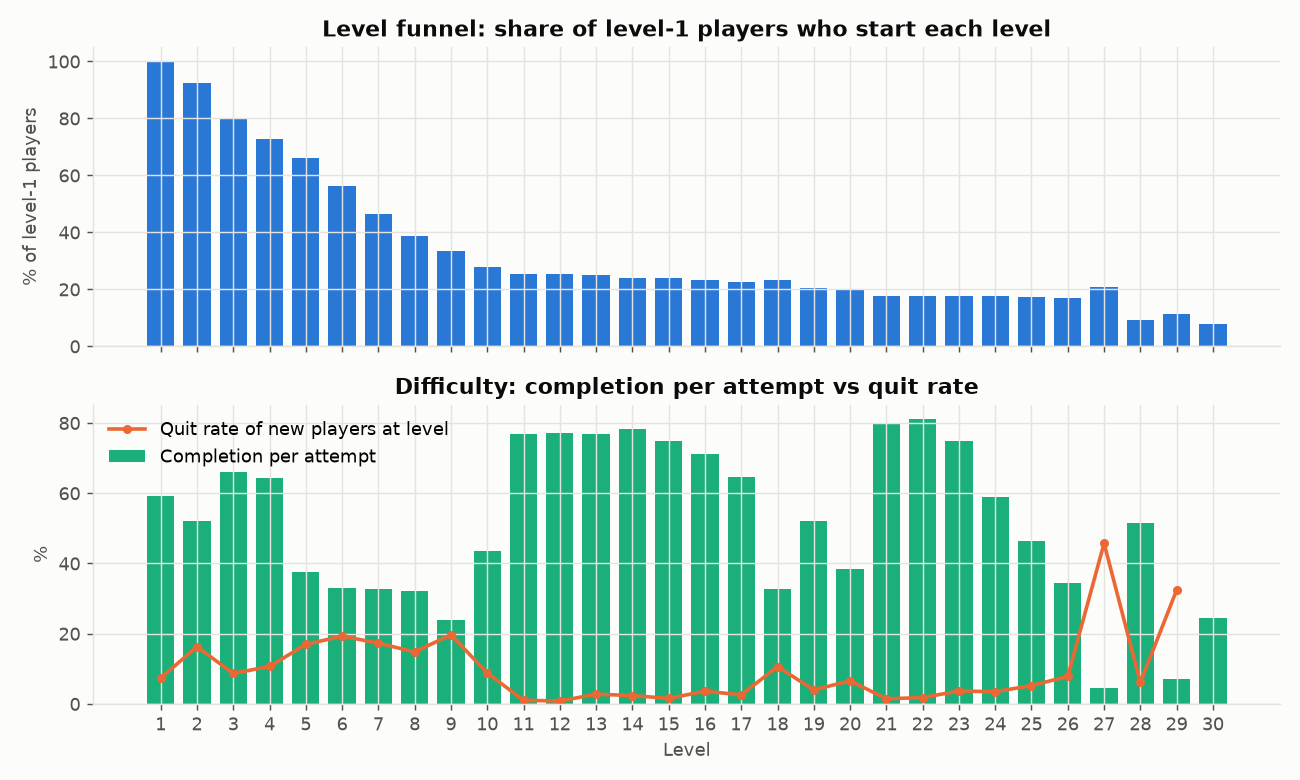

,level,users_started,reach_rate,completion_per_attempt,quit_rate_at_level
0,1,3509,1.000000,0.591076,0.073856
1,2,3247,0.925335,0.520768,0.162836
2,3,2795,0.796523,0.659265,0.086931
3,4,2558,0.728983,0.644173,0.106846
4,5,2325,0.662582,0.375881,0.169419
5,6,1970,0.561414,0.329358,0.193211
6,7,1627,0.463665,0.328753,0.173118
7,8,1362,0.388145,0.320803,0.148100
8,9,1179,0.335993,0.239704,0.196947
9,10,977,0.278427,0.435159,0.088123


In [12]:
fig('fig06_levels'); csv('p5_level_funnel')[['level','users_started','reach_rate','completion_per_attempt','quit_rate_at_level']]

In [13]:
display(csv('p5_level_anomalies')); csv('p5_quickplay_boards')

,level,starts,completes,fails,retries,resets,users_started,users_completed,users_failed
0,NaN,0,1272,0,0,0,0,193,0
1,0.0,0,0,143,0,0,0,0,65
2,31.0,0,0,0,185,0,0,0,0


,board,starts,completes,fails,players,completion_per_attempt,fail_per_attempt
0,L,44501,10344,23336,892,0.232444,0.524393
1,M,37290,13984,13784,786,0.375007,0.369643
2,S,441639,166760,99915,9235,0.377593,0.226237


## 6. Segments

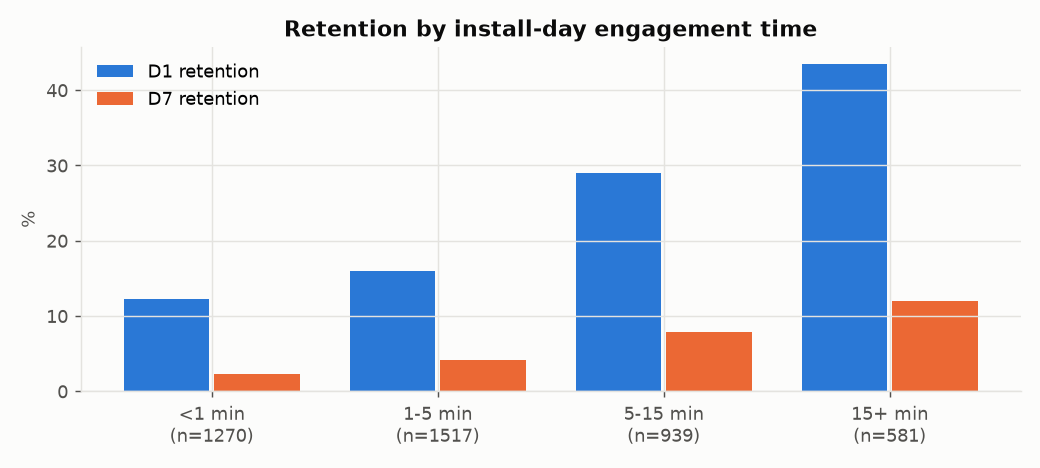

,dimension,segment,players,d1_eligible,d1_retention,d7_eligible,d7_retention,churn_eligible,churn_rate
0,Day-0 engagement time,<1 min,1270,1235,0.122267,1148,0.022648,872,0.821101
1,Day-0 engagement time,1-5 min,1517,1497,0.159653,1405,0.041993,1011,0.761622
2,Day-0 engagement time,5-15 min,939,935,0.289840,883,0.079275,656,0.634146
3,Day-0 engagement time,15+ min,581,572,0.435315,550,0.120000,416,0.550481
4,Day-0 sessions,0,495,491,0.099796,469,0.027719,364,0.810440
5,Day-0 sessions,1,3096,3047,0.184444,2844,0.045710,2121,0.743989
6,Day-0 sessions,2,485,475,0.381053,454,0.103524,319,0.561129
7,Day-0 sessions,3+,231,226,0.522124,219,0.141553,151,0.523179
8,Day-0 levels played,0,582,555,0.122523,512,0.021484,405,0.797531
9,Day-0 levels played,1-4,1485,1465,0.133106,1372,0.037172,986,0.775862


,segment,players,median_active_days,median_sessions,median_engagement_min,median_level_starts,median_quickplay_starts,share_watched_rewarded_ad
0,non-payer,15148,1,1,3.90136,0,2,0.023105
1,payer,27,3,4,23.76930,7,6,0.148148


In [14]:
fig('fig07_day0_engagement'); display(csv('p6_day0_segments')); csv('p6_payer_vs_nonpayer')

## 7. Churn prediction
Churned = no activity on day 7-30; features = install-day behaviour only.

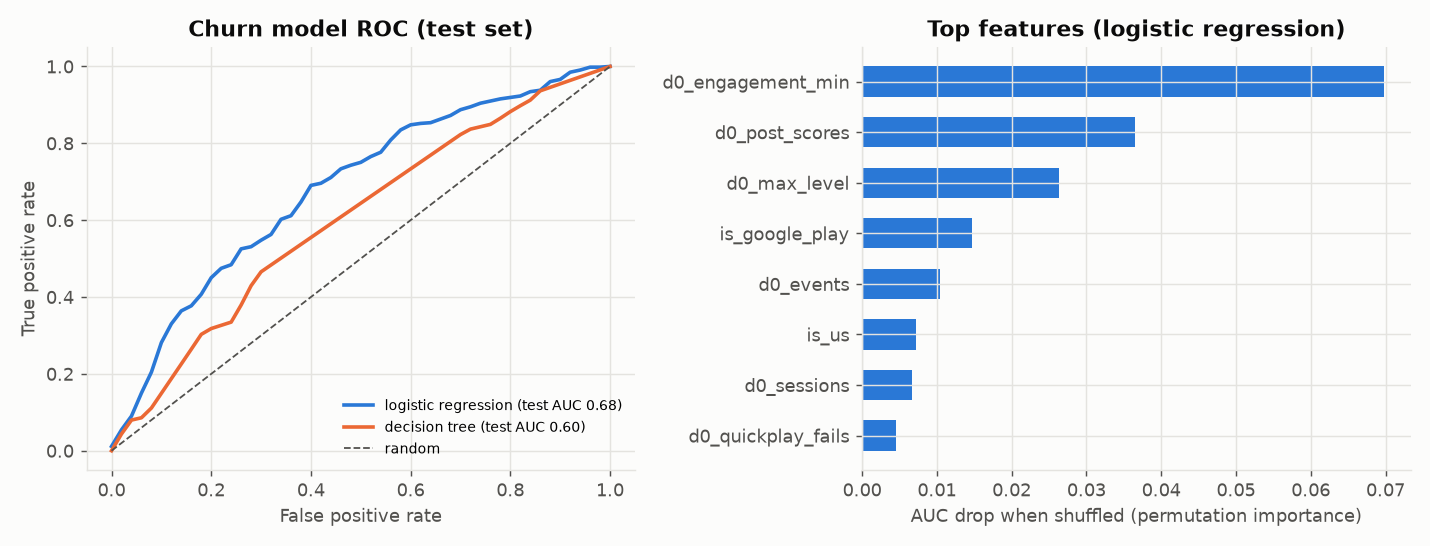

,model,cv_auc_mean,cv_auc_std,test_auc,train_n,test_n,test_churn_rate
0,logistic_regression,0.621192,0.038990,0.682649,2216,739,0.721245
1,decision_tree,0.609452,0.036336,0.602347,2216,739,0.721245


,risk_decile,players,churn_rate,avg_predicted
0,1,74,0.513514,0.282292
1,2,74,0.500000,0.371992
2,3,74,0.662162,0.423348
3,4,74,0.648649,0.463257
4,5,74,0.783784,0.497450
5,6,73,0.712329,0.527676
6,7,74,0.770270,0.562097
7,8,74,0.864865,0.599221
8,9,74,0.891892,0.633184
9,10,74,0.864865,0.686929


In [15]:
fig('fig08_churn_model'); display(csv('p7_model_performance')); csv('p7_risk_deciles')

In [16]:
print((ROOT / 'results/churn_tree_rules.txt').read_text())

|--- d0_engagement_min <= 1.78
|   |--- is_google_play <= 0.50
|   |   |--- d0_level_completes <= 0.50
|   |   |   |--- d0_events <= 12.50
|   |   |   |   |--- class: 1
|   |   |   |--- d0_events >  12.50
|   |   |   |   |--- class: 1
|   |   |--- d0_level_completes >  0.50
|   |   |   |--- d0_events <= 42.50
|   |   |   |   |--- class: 1
|   |   |   |--- d0_events >  42.50
|   |   |   |   |--- class: 1
|   |--- is_google_play >  0.50
|   |   |--- d0_engagement_min <= 0.06
|   |   |   |--- class: 1
|   |   |--- d0_engagement_min >  0.06
|   |   |   |--- is_us <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- is_us >  0.50
|   |   |   |   |--- class: 0
|--- d0_engagement_min >  1.78
|   |--- d0_sessions <= 1.50
|   |   |--- d0_events <= 297.50
|   |   |   |--- d0_level_starts <= 14.50
|   |   |   |   |--- class: 0
|   |   |   |--- d0_level_starts >  14.50
|   |   |   |   |--- class: 1
|   |   |--- d0_events >  297.50
|   |   |   |--- class: 0
|   |--- d0_sessions >  1.50
|   |   |-

## 8. Observational tests & A/B design
Observational comparisons, not randomised experiments.

,comparison,metric,group_a,group_b,n_a,x_a,rate_a,n_b,x_b,rate_b,diff_a_minus_b,diff_ci_low,diff_ci_high,z,p_value,chi2,chi2_p_value,cohens_h,relative_lift,note
0,Platform: iOS vs Android,D1 retention,IOS,ANDROID,1388,263,0.189481,2851,647,0.226938,-0.037457,-0.063175,-0.011738,-2.78725,5.315700e-03,7.76878,5.315700e-03,-0.092335,-0.165052,"Observational: platforms differ in audience, s..."
1,Traffic source (Android only): google-play vs ...,D1 retention,google-play,(direct),1325,351,0.264906,1459,287,0.196710,0.068196,0.036880,0.099511,4.27564,1.905880e-05,18.28110,1.905880e-05,0.162247,0.346681,Restricted to Android because iOS has no sourc...
2,Platform: iOS vs Android,D7 retention,IOS,ANDROID,1316,66,0.050152,2670,155,0.058052,-0.007900,-0.022656,0.006855,-1.02500,3.053610e-01,1.05063,3.053610e-01,-0.034946,-0.136092,"Observational: platforms differ in audience, s..."
3,Traffic source (Android only): google-play vs ...,D7 retention,google-play,(direct),1243,106,0.085278,1361,44,0.032329,0.052948,0.034799,0.071097,5.79235,6.940760e-09,33.55130,6.940760e-09,0.231110,1.637790,Restricted to Android because iOS has no sourc...


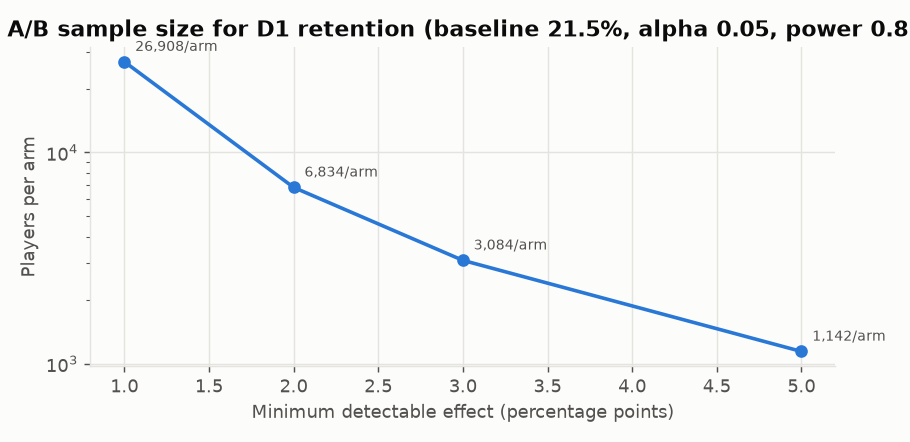

,metric,baseline,mde_abs,mde_relative,alpha,power,n_per_arm,total_n,sample_installs_per_day,days_needed_at_sample_volume,days_needed_incl_d1_lag
0,D1 retention,0.2147,0.01,0.046577,0.05,0.8,26908,53816,40.2617,1337,1338
1,D1 retention,0.2147,0.02,0.093153,0.05,0.8,6834,13668,40.2617,340,341
2,D1 retention,0.2147,0.03,0.139730,0.05,0.8,3084,6168,40.2617,154,155
3,D1 retention,0.2147,0.05,0.232883,0.05,0.8,1142,2284,40.2617,57,58


In [17]:
display(csv('p8_observational_tests')); fig('fig09_power'); csv('p8_power_analysis')

## 9. Validation

In [18]:
display(Markdown((ROOT / 'results/validation_report.md').read_text(encoding='utf-8')))

# Validation report

Every headline metric is computed **twice** - (A) SQL directly on raw Firebase events and (B) Pandas on player-level extracts - and compared automatically by `src/flood_it/validate.py`. Invariant checks catch logic errors that both methods could share.

**Result: 32 / 32 checks PASS.**

| Area | Check | Method A | Method B | Value A | Value B | Max abs diff | Status |
|---|---|---|---|---|---|---|---|
| Data | Total events: table inventory vs event catalogue | SQL 00 COUNT(*) per table | SQL 01 events by name | 5.7e+06 | 5.7e+06 | 0 | PASS |
| Data | Total events: raw vs player-day extract | SQL 00 | Pandas sum(user_day.events) | 5.7e+06 | 5.7e+06 | 0 | PASS |
| Data | Distinct players: users table vs player-day table | SQL 10 rows | Pandas nunique(user_day.user_id) | 15,175 | 15,175 | 0 | PASS |
| Growth | Daily DAU (114 days) | SQL 20 from raw events | Pandas daily_growth(user_day) | sum=59,037 | sum=59,037 | 0 | PASS |
| Growth | Daily INSTALLS (114 days) | SQL 20 from raw events | Pandas daily_growth(user_day) | sum=4,319 | sum=4,319 | 0 | PASS |
| Growth | Daily FIRST_SEEN_USERS (114 days) | SQL 20 from raw events | Pandas daily_growth(user_day) | sum=15,175 | sum=15,175 | 0 | PASS |
| Growth | Daily WAU (114 days) | SQL 20 from raw events | Pandas daily_growth(user_day) | sum=230,380 | sum=230,380 | 0 | PASS |
| Growth | Daily MAU (114 days) | SQL 20 from raw events | Pandas daily_growth(user_day) | sum=579,323 | sum=579,323 | 0 | PASS |
| Retention | Cohort-week x day-N cohort_users (85 cells) | SQL 30 from raw events | Pandas retention_table | sum=21,535 | sum=21,535 | 0 | PASS |
| Retention | Cohort-week x day-N eligible_users (85 cells) | SQL 30 from raw events | Pandas retention_table | sum=19,019 | sum=19,019 | 0 | PASS |
| Retention | Cohort-week x day-N retained_users (85 cells) | SQL 30 from raw events | Pandas retention_table | sum=1,759 | sum=1,759 | 0 | PASS |
| Retention | Pooled D1 retention | SQL 30 sum(retained)/sum(eligible) | Pandas | 0.214673 | 0.214673 | 0 | PASS |
| Retention | Pooled D3 retention | SQL 30 sum(retained)/sum(eligible) | Pandas | 0.104373 | 0.104373 | 0 | PASS |
| Retention | Pooled D7 retention | SQL 30 sum(retained)/sum(eligible) | Pandas | 0.0554441 | 0.0554441 | 0 | PASS |
| Retention | Pooled D14 retention | SQL 30 sum(retained)/sum(eligible) | Pandas | 0.0362162 | 0.0362162 | 0 | PASS |
| Retention | Pooled D30 retention | SQL 30 sum(retained)/sum(eligible) | Pandas | 0.0209814 | 0.0209814 | 0 | PASS |
| Revenue | active_users by platform (ALL/ANDROID/IOS) | SQL 40 from raw events | Pandas monetization_kpis | sum=30,350 | sum=30,350 | 0 | PASS |
| Revenue | user_days by platform (ALL/ANDROID/IOS) | SQL 40 from raw events | Pandas monetization_kpis | sum=118,074 | sum=118,074 | 0 | PASS |
| Revenue | payers by platform (ALL/ANDROID/IOS) | SQL 40 from raw events | Pandas monetization_kpis | sum=54 | sum=54 | 0 | PASS |
| Revenue | purchases by platform (ALL/ANDROID/IOS) | SQL 40 from raw events | Pandas monetization_kpis | sum=54 | sum=54 | 0 | PASS |
| Revenue | revenue_usd by platform (ALL/ANDROID/IOS) | SQL 40 from raw events | Pandas monetization_kpis | sum=63.7126 | sum=63.7126 | 0 | PASS |
| Levels | Level 1-30 starts | SQL 50 from raw events | Pandas from player x level (SQL 51) | sum=74,417 | sum=74,417 | 0 | PASS |
| Levels | Level 1-30 completes | SQL 50 from raw events | Pandas from player x level (SQL 51) | sum=32,714 | sum=32,714 | 0 | PASS |
| Levels | Level 1-30 fails | SQL 50 from raw events | Pandas from player x level (SQL 51) | sum=17,210 | sum=17,210 | 0 | PASS |
| Levels | Level 1-30 users_started | SQL 50 from raw events | Pandas from player x level (SQL 51) | sum=35,181 | sum=35,181 | 0 | PASS |
| Levels | Level 1-30 users_completed | SQL 50 from raw events | Pandas from player x level (SQL 51) | sum=26,505 | sum=26,505 | 0 | PASS |
| Sanity | D0 retention = 100% (every cohort player active on install day) | retention curve | invariant | D0=1.0000 |  | 0 | PASS |
| Sanity | Eligible players never increase with N (right-censoring) | retention curve | invariant | 4307 -> 2955 |  | 0 | PASS |
| Sanity | Fixed-population LTV curve is non-decreasing | ltv_curve | invariant | D0=0.002366, D30=0.002701 |  | 0 | PASS |
| Sanity | Every cohort player has install date inside the window | cohort | invariant | 2018-06-12..2018-10-03 |  | 0 | PASS |
| Sanity | Every purchase has a USD value (event_value_in_usd or USD fallback) | 12_iap | invariant | missing=0 |  | 0 | PASS |
| Sanity | DAU <= WAU <= MAU every day | daily growth | invariant | all 114 days |  | 0 | PASS |

AI-assisted development: mistakes caught during the build are logged in [docs/ai_corrections.md](../docs/ai_corrections.md).
